In [1]:
%pip install openplay

Note: you may need to restart the kernel to use updated packages.


In [2]:

import openplay as op
import pandas as pd

all_shots = []
op.competitions()

# Collect data from 2016/17 to 2025/26
for season_year in range(16, 26):
    season = f"{season_year}{season_year + 1}"
    shots = op.shots("ita", season)
    print(f"Collected {len(shots)} shots")
    all_shots.append(shots)

ita_shots = pd.concat(all_shots, ignore_index=True)

ita_shots.to_csv("ita_shots_2016_2025.csv", index=False)


HTTPError: HTTP Error 404: Not Found

In [6]:
%pip install pandas numpy matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

shots = pd.read_csv("ita_shots_2016_2025.csv")

# No own goals
shots = shots[~shots["is_own_goal"]].copy()
shots["is_goal"] = shots["is_goal"].astype(int)

# Convert OpenPlay field coordinates from 0–100 to 0–1. This is because of the new source
shots["location_x"] = shots["x"] / 100
shots["location_y"] = shots["y"] / 100

# Divide the field into zones
shots["x_zone"] = pd.cut(shots["location_x"], bins=np.linspace(0, 1, 11), include_lowest=True)
shots["y_zone"] = pd.cut(shots["location_y"], bins=np.linspace(0, 1, 11), include_lowest=True)

# Calculate stats for each zone
zone_stats = shots.groupby(
    ["x_zone", "y_zone"], observed=True
).agg(
    total_shots=("is_goal", "count"),
    goals=("is_goal", "sum"),
    avg_xg=("xg", "mean")
)

zone_stats["conversion_rate"] = (
    zone_stats["goals"] / zone_stats["total_shots"]
)

print(zone_stats.head(10))
print(zone_stats.tail(10))

                             total_shots  goals  avg_xg  conversion_rate
x_zone        y_zone                                                    
(-0.001, 0.1] (0.8, 0.9]               1      0     NaN              0.0
(0.2, 0.3]    (-0.001, 0.1]            1      0     NaN              0.0
              (0.1, 0.2]               1      0     NaN              0.0
              (0.9, 1.0]               1      0     NaN              0.0
(0.3, 0.4]    (0.2, 0.3]               3      0     NaN              0.0
              (0.3, 0.4]               2      0     NaN              0.0
              (0.4, 0.5]               5      0     NaN              0.0
              (0.5, 0.6]               5      0     NaN              0.0
              (0.6, 0.7]               7      0     NaN              0.0
              (0.7, 0.8]               4      0     NaN              0.0
                          total_shots  goals    avg_xg  conversion_rate
x_zone     y_zone                                   

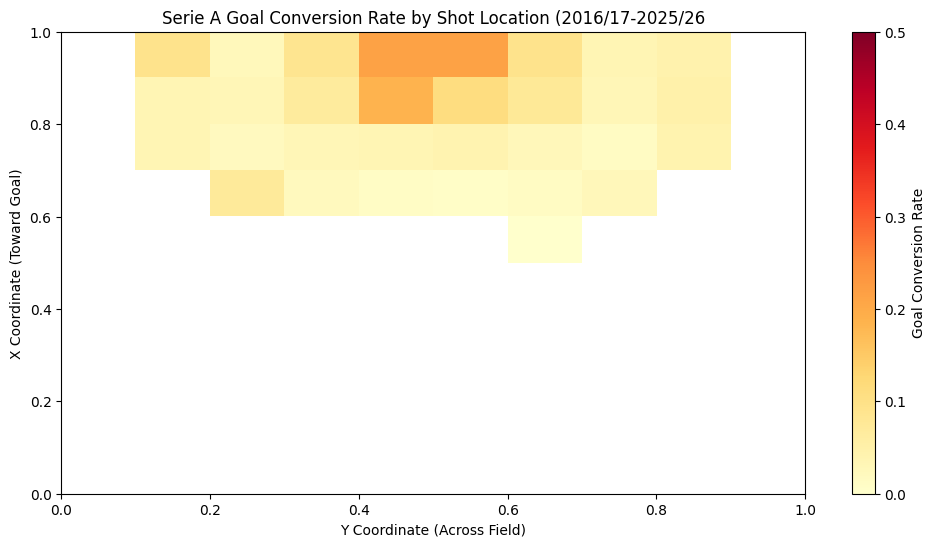

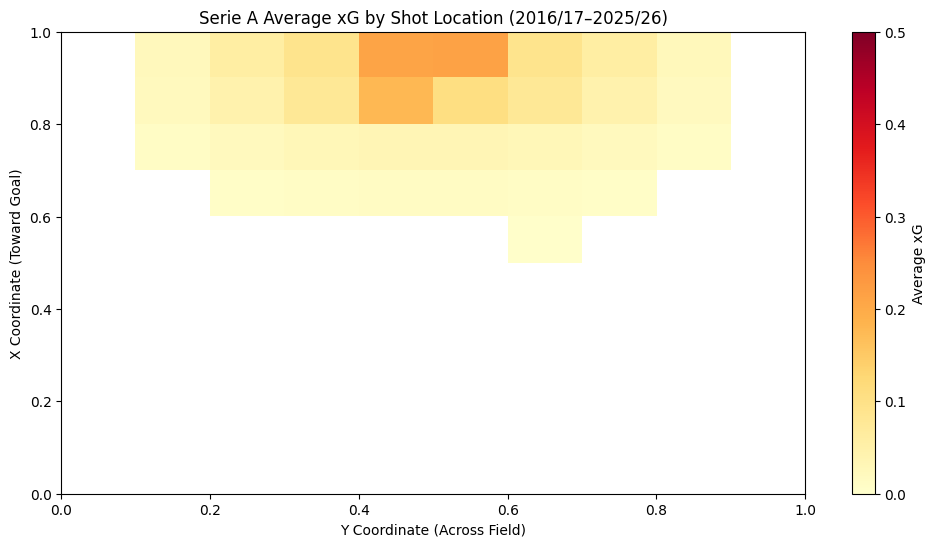

In [35]:
x_zones = shots["x_zone"].cat.categories
y_zones = shots["y_zone"].cat.categories

# Create grids using the correct categories
conversion_grid = zone_stats["conversion_rate"].unstack()
xg_grid = zone_stats["avg_xg"].unstack()
shot_count_grid = zone_stats["total_shots"].unstack().reindex(index=x_zones, columns=y_zones)

# Reindex using the original interval categories
conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)

# Filter out zones with less than 30 shots
conversion_grid = conversion_grid.where(shot_count_grid >= 30)
xg_grid = xg_grid.where(shot_count_grid >= 30)


# Conversion rate heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    conversion_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Goal Conversion Rate")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("Serie A Goal Conversion Rate by Shot Location (2016/17-2025/26")

plt.show()

# Average xG heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    xg_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Average xG")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("Serie A Average xG by Shot Location (2016/17–2025/26)")

plt.show()

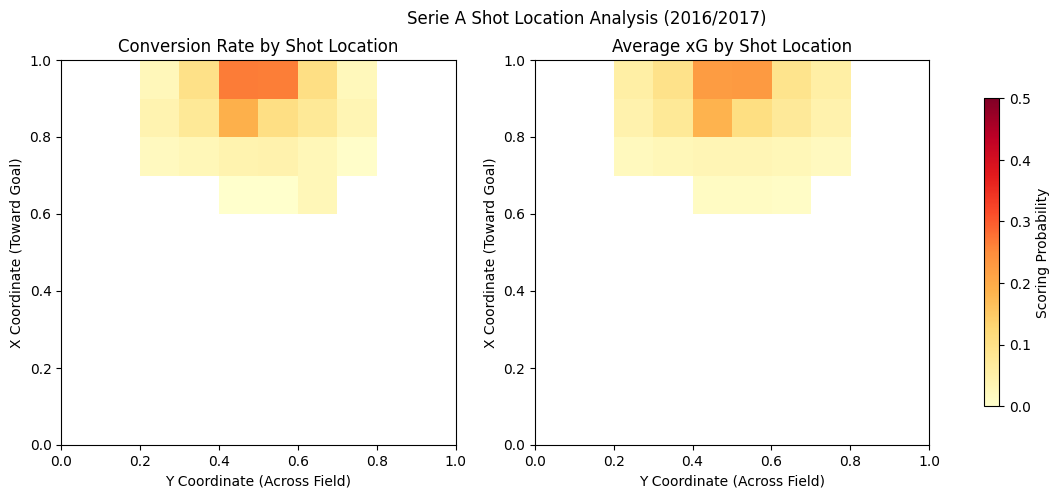

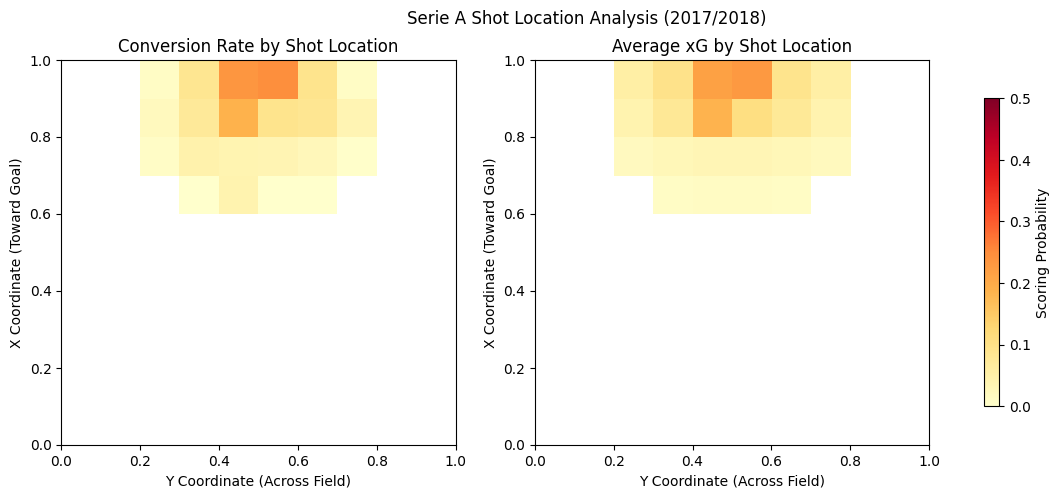

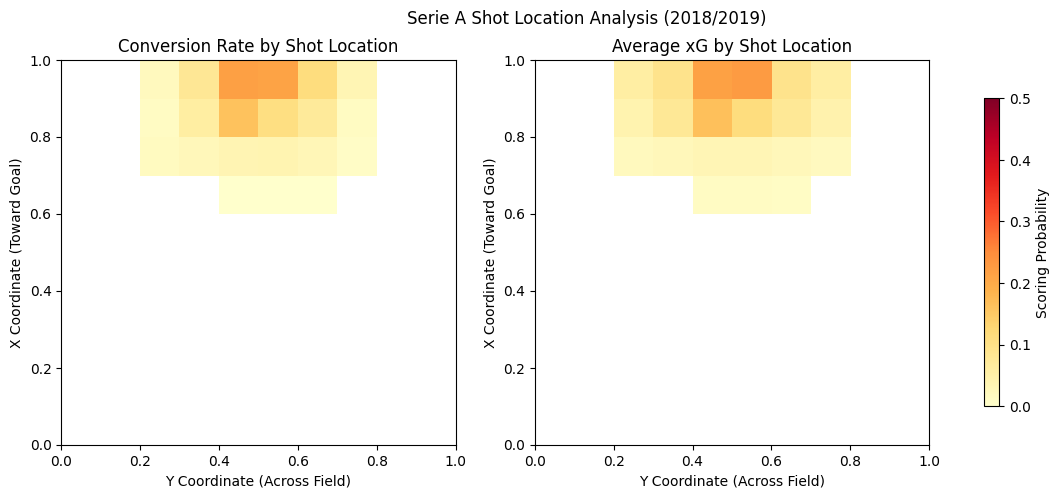

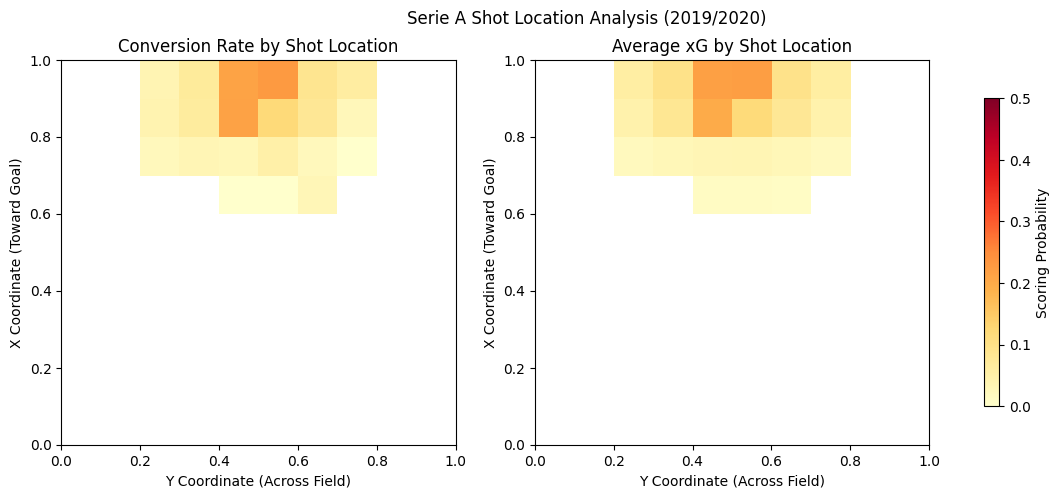

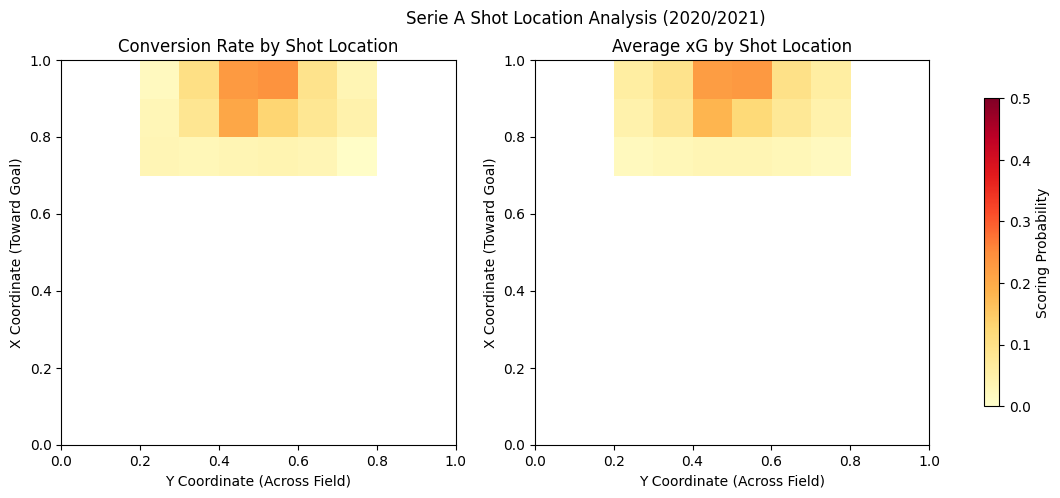

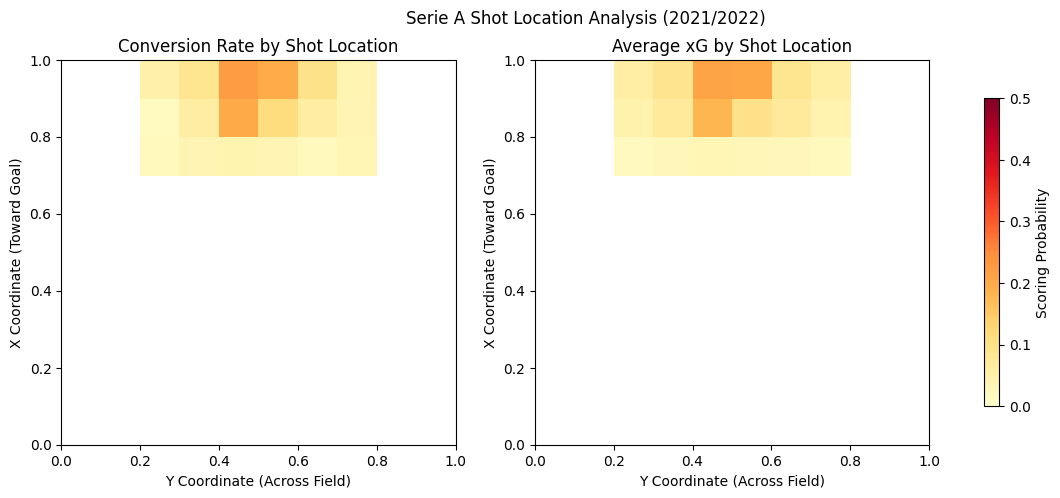

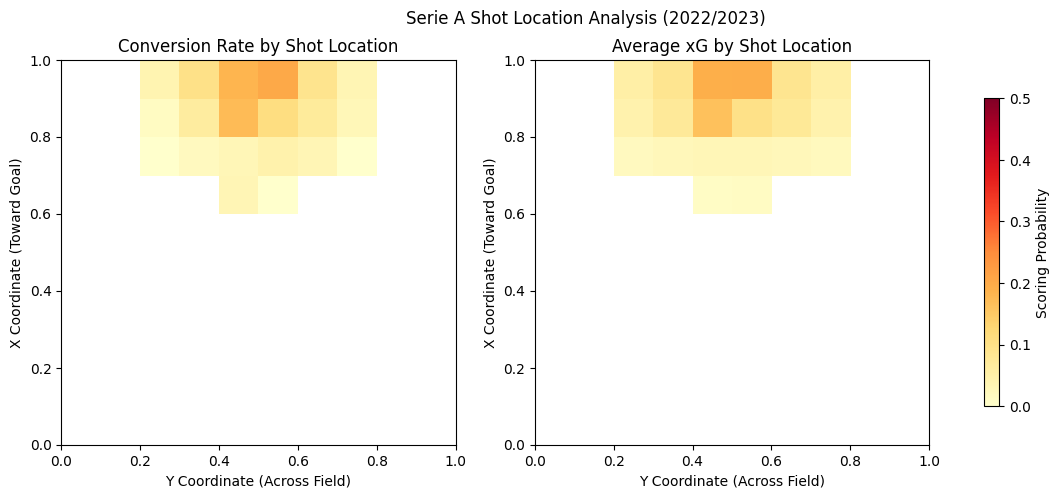

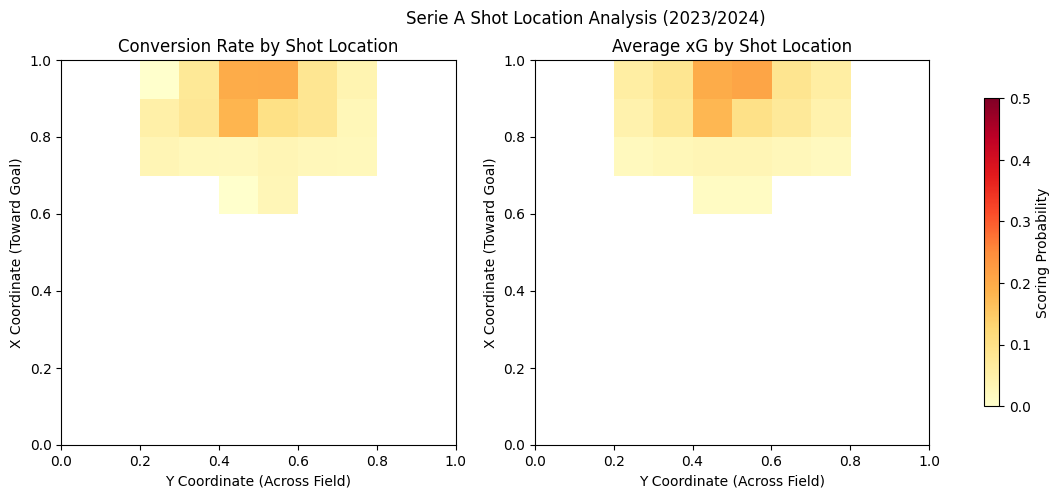

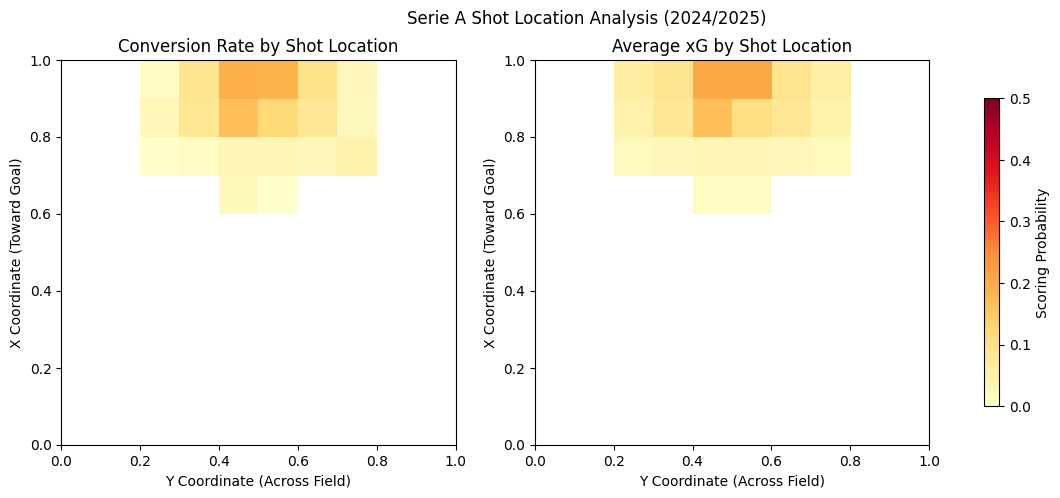

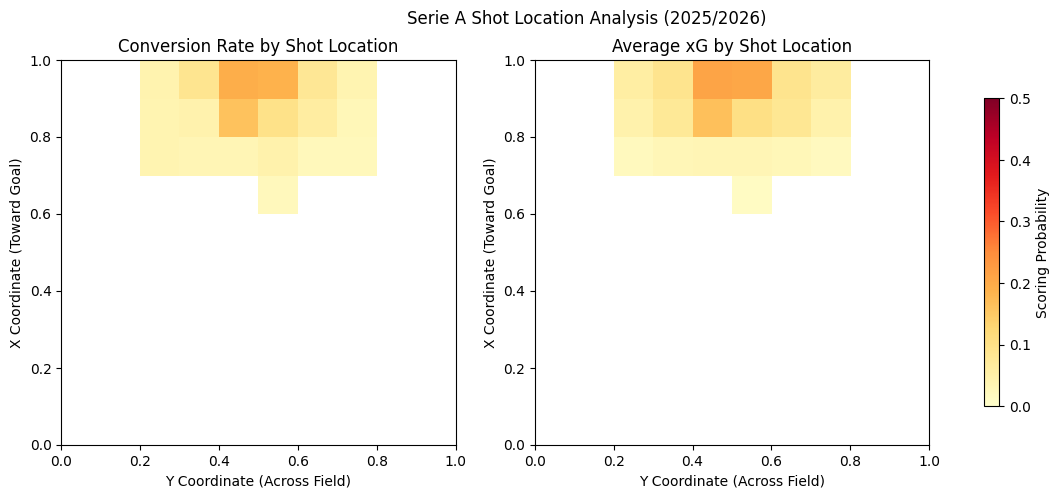

In [36]:
season_zone_stats = shots.groupby(
    ["season", "x_zone", "y_zone"],
    observed=True
).agg(
    total_shots=("is_goal", "count"),
    goals=("is_goal", "sum"),
    avg_xg=("xg", "mean")
)

season_zone_stats["conversion_rate"] = (
    season_zone_stats["goals"] / season_zone_stats["total_shots"]
)

for season in sorted(shots["season"].unique()):

    # Get statistics for this season
    season_data = season_zone_stats.loc[season]

    conversion_grid = season_data["conversion_rate"].unstack()
    xg_grid = season_data["avg_xg"].unstack()
    shot_count_grid = season_data["total_shots"].unstack()

    conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
    xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)
    shot_count_grid = shot_count_grid.reindex(index=x_zones, columns=y_zones)

    # Filter out zones with less than 30 shots
    conversion_grid = conversion_grid.where(shot_count_grid >= 30)
    xg_grid = xg_grid.where(shot_count_grid >= 30)

    # Display two heatmaps side by side
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].imshow(
        conversion_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[0].set_title("Conversion Rate by Shot Location")
    axes[0].set_xlabel("Y Coordinate (Across Field)")
    axes[0].set_ylabel("X Coordinate (Toward Goal)")

    im = axes[1].imshow(
        xg_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[1].set_title("Average xG by Shot Location")
    axes[1].set_xlabel("Y Coordinate (Across Field)")
    axes[1].set_ylabel("X Coordinate (Toward Goal)")

    fig.colorbar(im, ax=axes, label="Scoring Probability", shrink=0.8)
    fig.suptitle(f"Serie A Shot Location Analysis (20{str(season)[:2]}/20{str(season)[2:]})")

    plt.show()

Question 2: Are teams that create more chances from open play more successful than set piece dependent teams?

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ita_shots_2016_2025.csv")

# Use the season starting year (1617 -> 2016)
df["season"] = 2000 + df["season"] // 100

print("Total shots:", len(df))
print("Seasons:", sorted(df["season"].unique()))
print("Teams:", df["team_id"].nunique())

display(df.head())

Total shots: 98702
Seasons: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Teams: 34


,comp,season,match_id,event_id,event_id_sub,team_event_id,period,minute,second,expanded_minute,...,goal_mouth_z,blocked_x,blocked_y,xg,assist_player_id,assist_player,assist_type,assist_event_type,assist_event_id,xg_model
0,ita,2016,1115149,788558229,0,67,FirstHalf,7,9,7,...,NaN,88.6,29.1,0.041922,26587.0,Marco Parolo,pass,Pass,5.796084e+08,openplay_xg_v1
1,ita,2016,1115149,2068425916,0,68,FirstHalf,7,10,7,...,1.9,97.3,46.4,0.054451,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1
2,ita,2016,1115149,313938017,0,86,FirstHalf,7,36,7,...,NaN,88.9,55.8,0.149108,92329.0,Leonardo Spinazzola,pass,Pass,1.587856e+09,openplay_xg_v1
3,ita,2016,1115149,1633334497,0,132,FirstHalf,11,34,11,...,NaN,81.2,48.0,0.025763,22546.0,Papu Gómez,pass,Pass,2.101653e+09,openplay_xg_v1
4,ita,2016,1115149,1917714270,0,137,FirstHalf,12,10,12,...,86.1,NaN,NaN,0.017326,NaN,NaN,NaN,NaN,NaN,openplay_xg_v1


In [38]:
# Classify shot situations (penalties count as set pieces)
df["shot_category"] = np.where(
    df["is_set_piece"] | df["is_penalty"], "Set Piece", "Open Play"
)

# Goal and own-goal flags are already in the OpenPlay CSV
df["is_goal"] = df["is_goal"].astype(int)
df["is_own_goal"] = df["is_own_goal"].astype(int)

# Exclude own goals
shots = df[df["is_own_goal"] == 0].copy()

print(shots["shot_category"].value_counts())

shot_category
Open Play    72586
Set Piece    25803
Name: count, dtype: int64


In [39]:
category_stats = (
    shots.groupby("shot_category")
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        Total_xG=("xg", "sum"),
        Average_xG=("xg", "mean")
    )
    .reset_index()
)

category_stats["Conversion_Rate"] = (
    category_stats["Goals"] / category_stats["Shots"] * 100
)

category_stats["Average_xG"] *= 100

display(category_stats.round(2))

,shot_category,Shots,Goals,Total_xG,Average_xG,Conversion_Rate
0,Open Play,72586,7150,6777.20,9.35,9.85
1,Set Piece,25803,2928,3257.48,12.63,11.35


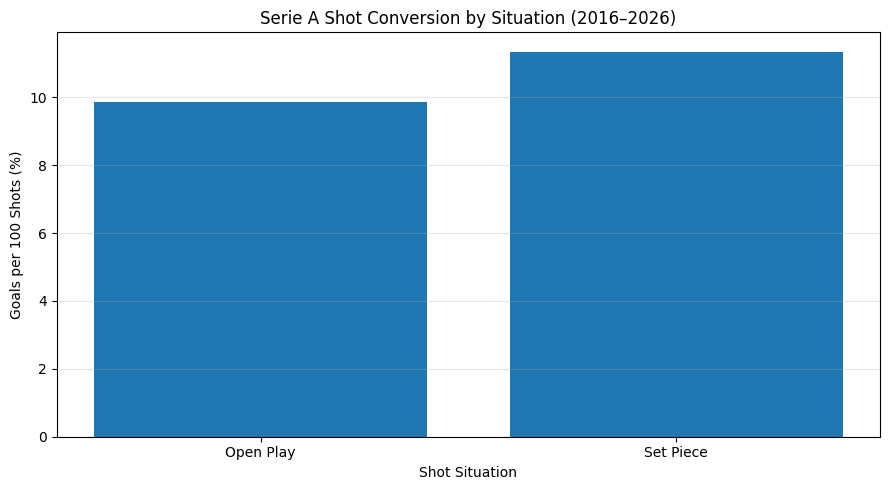

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_stats["shot_category"],
    category_stats["Conversion_Rate"]
)

plt.title("Serie A Shot Conversion by Situation (2016–2026)")
plt.xlabel("Shot Situation")
plt.ylabel("Goals per 100 Shots (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [41]:
# Focus on the two main categories
main_shots = shots[
    shots["shot_category"].isin(["Open Play", "Set Piece"])
].copy()

team_stats = (
    main_shots.groupby(
        ["season", "team_id", "shot_category"]
    )
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .unstack(fill_value=0)
)

# Flatten the column names
team_stats.columns = [
    f"{metric}_{category.replace(' ', '_')}"
    for metric, category in team_stats.columns
]

team_stats = team_stats.reset_index()

for category in ["Open_Play", "Set_Piece"]:
    for metric in ["Shots", "Goals", "xG"]:
        column = f"{metric}_{category}"
        if column not in team_stats.columns:
            team_stats[column] = 0

team_stats["Total_Shots"] = (
    team_stats["Shots_Open_Play"] +
    team_stats["Shots_Set_Piece"]
)

team_stats["Set_Piece_Share"] = (
    team_stats["Shots_Set_Piece"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Open_Play_Share"] = (
    team_stats["Shots_Open_Play"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Set_Piece_Conversion"] = (
    team_stats["Goals_Set_Piece"] /
    team_stats["Shots_Set_Piece"].replace(0, np.nan) * 100
)

team_stats["Open_Play_Conversion"] = (
    team_stats["Goals_Open_Play"] /
    team_stats["Shots_Open_Play"].replace(0, np.nan) * 100
)

display(team_stats.head())

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion
0,2016,71,323,100,32,7,28.004962,7.139273,423,23.640662,76.359338,7.000000,9.907121
1,2016,72,425,151,48,23,33.414147,20.229489,576,26.215278,73.784722,15.231788,11.294118
2,2016,73,475,139,45,17,36.750857,18.039483,614,22.638436,77.361564,12.230216,9.473684
3,2016,75,456,179,51,19,47.276421,19.259901,635,28.188976,71.811024,10.614525,11.184211
4,2016,77,428,163,44,29,37.990379,23.553443,591,27.580372,72.419628,17.791411,10.280374


In [42]:
# Find two teams per match
match_teams = df[["match_id", "season", "team_id"]].drop_duplicates()
match_teams = match_teams[
    match_teams.groupby(["season", "match_id"])["team_id"].transform("size").eq(2)
].copy()

# Count normal goals and own goals per team
normal_goals = (
    df[(df["is_goal"] == 1) & (df["is_own_goal"] == 0)]
    .groupby(["season", "match_id", "team_id"])
    .size().reset_index(name="normal_goals")
)
own_goals = (
    df[df["is_own_goal"] == 1]
    .groupby(["season", "match_id", "team_id"])
    .size().reset_index(name="own_goals_by")
)

scores = (match_teams
    .merge(normal_goals, on=["season", "match_id", "team_id"], how="left")
    .merge(own_goals, on=["season", "match_id", "team_id"], how="left")
)
scores[["normal_goals", "own_goals_by"]] = scores[["normal_goals", "own_goals_by"]].fillna(0)

# Award own goals to the other team
match_goals = scores.groupby(["season", "match_id"])[["normal_goals", "own_goals_by"]].transform("sum")
scores["goals_for"] = scores["normal_goals"] + match_goals["own_goals_by"] - scores["own_goals_by"]
scores["goals_against"] = match_goals["normal_goals"] + match_goals["own_goals_by"] - scores["goals_for"]

# Calculate match points
scores["Points"] = np.select(
    [scores["goals_for"] > scores["goals_against"],
     scores["goals_for"] == scores["goals_against"]],
    [3, 1], default=0
)

# Calculate points earned by each team each season
team_points = (
    scores.groupby(["season", "team_id"])
    .agg(Matches=("match_id", "nunique"), Points=("Points", "sum"))
    .reset_index()
)
team_points["Points_Per_Game"] = team_points["Points"] / team_points["Matches"]

# Combine team performance with shot statistics
team_stats = team_stats.merge(team_points, on=["season", "team_id"], how="inner")

display(team_stats.head())
print("Note: points are reconstructed from shot event goals, not official standings.")

,season,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion,Matches,Points,Points_Per_Game
0,2016,71,323,100,32,7,28.004962,7.139273,423,23.640662,76.359338,7.000000,9.907121,38,41,1.078947
1,2016,72,425,151,48,23,33.414147,20.229489,576,26.215278,73.784722,15.231788,11.294118,38,53,1.394737
2,2016,73,475,139,45,17,36.750857,18.039483,614,22.638436,77.361564,12.230216,9.473684,38,60,1.578947
3,2016,75,456,179,51,19,47.276421,19.259901,635,28.188976,71.811024,10.614525,11.184211,38,62,1.631579
4,2016,77,428,163,44,29,37.990379,23.553443,591,27.580372,72.419628,17.791411,10.280374,38,70,1.842105


Note: points are reconstructed from shot event goals, not official standings.


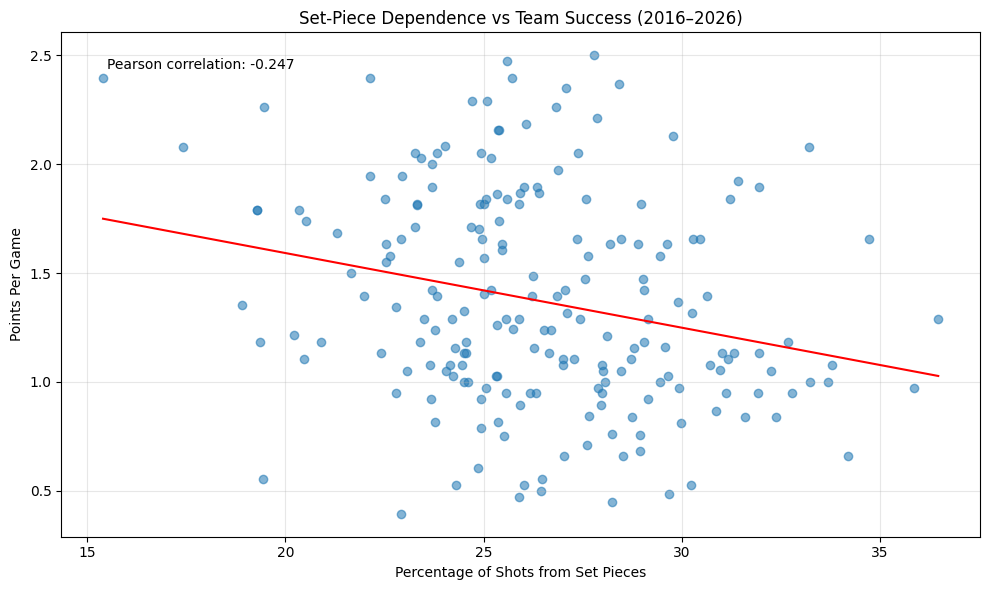

Correlation: -0.247


In [43]:
plt.figure(figsize=(10, 6))

plt.scatter(
    team_stats["Set_Piece_Share"],
    team_stats["Points_Per_Game"],
    alpha=0.55
)

# Calculate correlation
correlation = team_stats[
    ["Set_Piece_Share", "Points_Per_Game"]
].corr().iloc[0, 1]

# Add trend line
x = team_stats["Set_Piece_Share"]
y = team_stats["Points_Per_Game"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, slope * x_line + intercept, color="red")

plt.title("Set-Piece Dependence vs Team Success (2016–2026)")
plt.xlabel("Percentage of Shots from Set Pieces")
plt.ylabel("Points Per Game")

plt.text(
    0.05, 0.95,
    f"Pearson correlation: {correlation:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation:", round(correlation, 3))

In [44]:
median_share = team_stats["Set_Piece_Share"].median()

team_stats["Playstyle"] = np.where(
    team_stats["Set_Piece_Share"] >= median_share,
    "More Set-Piece Dependent",
    "More Open-Play Dependent"
)

playstyle_results = (
    team_stats.groupby("Playstyle")
    .agg(
        Teams_Seasons=("team_id", "count"),
        Avg_Points_Per_Game=("Points_Per_Game", "mean"),
        Avg_Open_Play_Goals=("Goals_Open_Play", "mean"),
        Avg_Set_Piece_Goals=("Goals_Set_Piece", "mean"),
        Avg_Set_Piece_Share=("Set_Piece_Share", "mean")
    )
)

display(playstyle_results.round(2))

,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.47,39.69,14.23,23.66
More Set-Piece Dependent,100,1.28,31.81,15.05,29.18


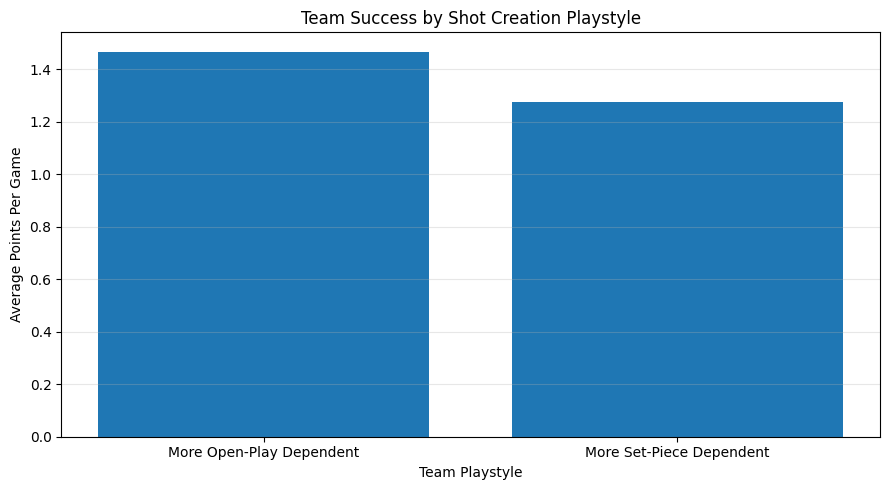

In [45]:
plt.figure(figsize=(9, 5))

plt.bar(
    playstyle_results.index,
    playstyle_results["Avg_Points_Per_Game"]
)

plt.title("Team Success by Shot Creation Playstyle")
plt.xlabel("Team Playstyle")
plt.ylabel("Average Points Per Game")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


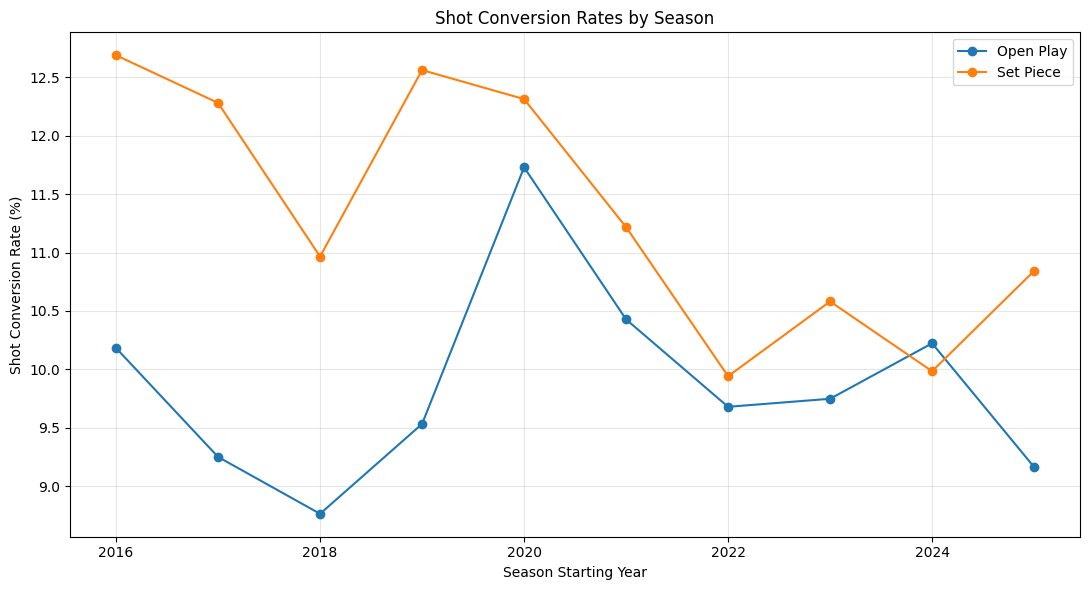

In [46]:
season_trends = (
    main_shots.groupby(["season", "shot_category"])
    .agg(
        Shots=("event_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .reset_index()
)

season_trends["Conversion_Rate"] = (
    season_trends["Goals"] /
    season_trends["Shots"] * 100
)

# Compare shot conversion rates over time
conversion_trends = season_trends.pivot(
    index="season",
    columns="shot_category",
    values="Conversion_Rate"
)

plt.figure(figsize=(11, 6))

for category in conversion_trends.columns:
    plt.plot(
        conversion_trends.index,
        conversion_trends[category],
        marker="o",
        label=category
    )

plt.title("Shot Conversion Rates by Season")
plt.xlabel("Season Starting Year")
plt.ylabel("Shot Conversion Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

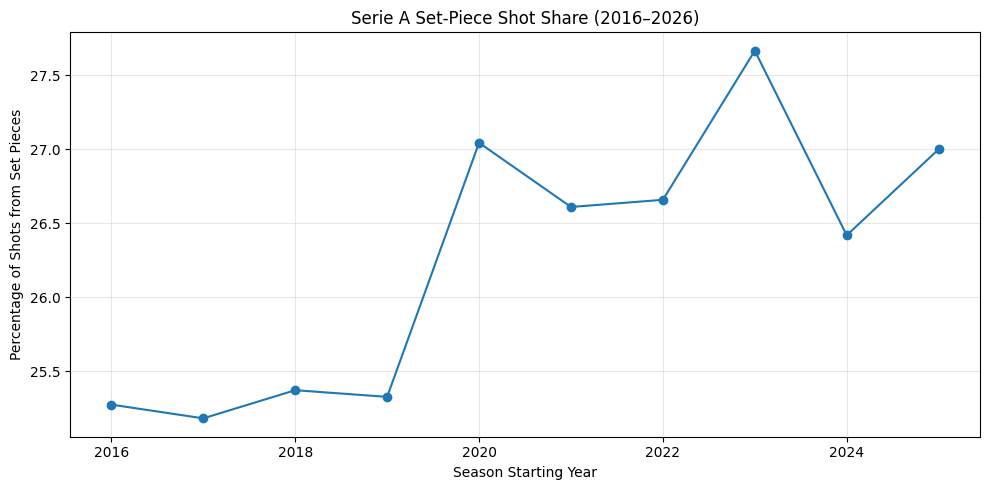

shot_category,Open Play,Set Piece,Set_Piece_Percentage
season,,,
2016,7572,2561,25.27
2017,7330,2467,25.18
2018,7886,2681,25.37
2019,8120,2754,25.33
2020,6922,2566,27.04
2021,7154,2594,26.61
2022,6974,2535,26.66
2023,7017,2684,27.67
2024,6779,2434,26.42


In [47]:
season_shares = (
    main_shots.groupby(["season", "shot_category"])
    .size()
    .unstack(fill_value=0)
)

season_shares["Set_Piece_Percentage"] = (
    season_shares["Set Piece"] /
    (season_shares["Open Play"] + season_shares["Set Piece"]) * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    season_shares.index,
    season_shares["Set_Piece_Percentage"],
    marker="o"
)

plt.title("Serie A Set-Piece Shot Share (2016–2026)")
plt.xlabel("Season Starting Year")
plt.ylabel("Percentage of Shots from Set Pieces")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(season_shares.round(2))

In [48]:
from scipy.stats import ttest_ind

set_piece_teams = team_stats[
    team_stats["Playstyle"] == "More Set-Piece Dependent"
]["Points_Per_Game"]

open_play_teams = team_stats[
    team_stats["Playstyle"] == "More Open-Play Dependent"
]["Points_Per_Game"]

t_stat, p_value = ttest_ind(
    set_piece_teams,
    open_play_teams,
    equal_var=False
)

print("Set-piece group average PPG:", round(set_piece_teams.mean(), 3))
print("Open-play group average PPG:", round(open_play_teams.mean(), 3))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference at alpha = 0.05")
else:
    print("No statistically significant difference at alpha = 0.05")

Set-piece group average PPG: 1.276
Open-play group average PPG: 1.467
T-statistic: -2.7952
P-value: 0.0057
Statistically significant difference at alpha = 0.05


In [49]:
print("SERIE A SHOT ANALYSIS")
print("2016-17 through 2025-26")
print("-" * 45)

print("\nShot conversion rates:")
display(category_stats[
    ["shot_category", "Shots", "Goals", "Conversion_Rate"]
].round(2))

print("\nPlaystyle comparison:")
display(playstyle_results.round(2))

print("\nSet-piece dependence vs points per game:")
print(f"Pearson correlation: {correlation:.3f}")

print("\nStatistical comparison:")
print(f"P-value: {p_value:.4f}")

print("\nSet-piece shot share by season:")
display(season_shares[["Set_Piece_Percentage"]].round(2))


SERIE A SHOT ANALYSIS
2016-17 through 2025-26
---------------------------------------------

Shot conversion rates:


,shot_category,Shots,Goals,Conversion_Rate
0,Open Play,72586,7150,9.85
1,Set Piece,25803,2928,11.35



Playstyle comparison:


,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.47,39.69,14.23,23.66
More Set-Piece Dependent,100,1.28,31.81,15.05,29.18



Set-piece dependence vs points per game:
Pearson correlation: -0.247

Statistical comparison:
P-value: 0.0057

Set-piece shot share by season:


shot_category,Set_Piece_Percentage
season,
2016,25.27
2017,25.18
2018,25.37
2019,25.33
2020,27.04
2021,26.61
2022,26.66
2023,27.67
2024,26.42


Question 3: Which teams have the largest differences in actual points and expected points?

In [50]:
from scipy.stats import poisson

matchdf = pd.read_csv("ita_shots_2016_2025.csv")

# Use the season starting year (1617 -> 2016)
matchdf["season"] = 2000 + matchdf["season"] // 100

# Preprocessing to handle own goals and xG
matchdf["is_goal"] = (matchdf["is_goal"] & ~matchdf["is_own_goal"]).astype(int)
matchdf["is_own_goal"] = matchdf["is_own_goal"].astype(int)
matchdf["xg_valid"] = matchdf["xg"].where(matchdf["is_own_goal"] == 0, 0)

# One row per team per match
teamGames = (matchdf.groupby(["season", "match_id", "team_id", "team"], as_index=False)
    .agg(xg_for=("xg_valid", "sum"),
         missing_xg=("xg_valid", lambda values: values.isna().any()),
         goals_scored=("is_goal", "sum"),
         own_goals_by=("is_own_goal", "sum")))

# Keep matches where both teams have shot records
complete = teamGames.groupby(["season", "match_id"])["team_id"].transform("nunique") == 2
teamGames = teamGames[complete].copy()

# Gather match stats, including own goals awarded to opponents
singleGame = teamGames.groupby(["season", "match_id"])
xgTotal = singleGame["xg_for"].transform("sum")
ownGoalsTotal = singleGame["own_goals_by"].transform("sum")
goalsTotal = singleGame["goals_scored"].transform("sum") + ownGoalsTotal

teamGames["goals_for"] = teamGames["goals_scored"] + ownGoalsTotal - teamGames["own_goals_by"]
teamGames["goals_against"] = goalsTotal - teamGames["goals_for"]
teamGames["xg_against"] = xgTotal - teamGames["xg_for"]

# Actual match points from reconstructed scores
teamGames["Points"] = np.select(
    [teamGames["goals_for"] > teamGames["goals_against"],
     teamGames["goals_for"] == teamGames["goals_against"]], [3, 1], default=0
)

# Do not calculate expected points for matches with missing xG
complete_xg = ~teamGames.groupby(["season", "match_id"])["missing_xg"].transform("any")
teamGames = teamGames[complete_xg].copy()

# Calculate expected match points from xG using a Poisson goal model
# Expected points = 3 * P(win) + P(draw)
k = np.arange(31)
for_xg = teamGames["xg_for"].to_numpy()[:, None]
against_xg = teamGames["xg_against"].to_numpy()[:, None]
p_win = (poisson.pmf(k, for_xg) * poisson.cdf(k - 1, against_xg)).sum(axis=1)
p_draw = (poisson.pmf(k, for_xg) * poisson.pmf(k, against_xg)).sum(axis=1)
teamGames["xPts"] = 3 * p_win + p_draw

# One row per team per season
seasonTable = (teamGames.groupby(["season", "team_id", "team"], as_index=False)
    .agg(matches=("match_id", "count"),
         actual_points=("Points", "sum"), expected_points=("xPts", "sum"),
         goals_for=("goals_for", "sum"), xg_for=("xg_for", "sum"),
         goals_against=("goals_against", "sum"), xg_against=("xg_against", "sum")))

seasonTable["points_diff"] = seasonTable["actual_points"] - seasonTable["expected_points"]
seasonTable["gf_diff"] = seasonTable["goals_for"] - seasonTable["xg_for"]
seasonTable["ga_diff"] = seasonTable["goals_against"] - seasonTable["xg_against"]
seasonTable["xg_diff"] = seasonTable["xg_for"] - seasonTable["xg_against"]
seasonTable["team_season"] = seasonTable["team"] + " (" + seasonTable["season"].astype(str) + ")"

print("Biggest single season points overperformers:")
display(seasonTable.sort_values("points_diff", ascending=False).head(10).round(1))

print("\nBiggest single season points underperformers:")
display(seasonTable.sort_values("points_diff").head(10).round(1))

print("Note: expected points use a Poisson model; points come from recorded shot-event goals.")

Biggest single season points overperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
30,2017,87,Juventus,37,92,67.3,85,53.4,24,27.7,24.7,31.6,-3.7,25.7,Juventus (2017)
83,2020,75,Inter,38,91,71.4,89,72.3,35,41.0,19.6,16.7,-6.0,31.4,Inter (2020)
107,2021,80,AC Milan,38,86,67.0,69,60.9,31,36.5,19.0,8.1,-5.5,24.4,AC Milan (2021)
49,2018,87,Juventus,36,84,65.1,67,58.9,29,33.7,18.9,8.1,-4.7,25.2,Juventus (2018)
33,2017,276,Napoli,32,81,62.4,65,51.5,21,22.8,18.6,13.5,-1.8,28.7,Napoli (2017)
65,2019,77,Lazio,34,74,55.9,71,58.8,35,43.7,18.1,12.2,-8.7,15.1,Lazio (2019)
125,2022,77,Lazio,37,71,53.1,57,44.9,29,40.0,17.9,12.1,-11.0,4.9,Lazio (2022)
143,2023,75,Inter,38,94,76.2,89,77.0,22,34.0,17.8,12.0,-12.0,43.0,Inter (2023)
135,2022,276,Napoli,36,84,67.5,75,59.0,28,30.9,16.5,16.0,-2.9,28.1,Napoli (2022)
175,2024,276,Napoli,38,82,66.1,59,55.5,27,32.5,15.9,3.5,-5.5,23.0,Napoli (2024)



Biggest single season points underperformers:


,season,team_id,team,matches,actual_points,expected_points,goals_for,xg_for,goals_against,xg_against,points_diff,gf_diff,ga_diff,xg_diff,team_season
14,2016,277,Pescara,38,15,43.8,35,44.6,83,59.6,-28.8,-9.6,23.4,-15.0,Pescara (2016)
184,2025,76,Verona,35,18,41.5,21,34.3,57,44.4,-23.5,-13.3,12.6,-10.1,Verona (2025)
195,2025,777,Pisa,36,18,40.3,25,39.5,65,57.1,-22.3,-14.5,7.9,-17.6,Pisa (2025)
99,2020,24341,Parma Calcio 1913,38,20,42.1,39,41.2,83,58.0,-22.1,-2.2,25.0,-16.8,Parma Calcio 1913 (2020)
77,2019,1502,SPAL,38,20,39.5,27,43.0,77,64.4,-19.5,-16.0,12.6,-21.4,SPAL (2019)
173,2024,269,Monza,36,14,32.7,25,29.0,69,53.7,-18.7,-4.0,15.3,-24.7,Monza (2024)
50,2018,267,Chievo,38,20,37.5,25,36.6,75,59.9,-17.5,-11.6,15.1,-23.3,Chievo (2018)
42,2018,73,Fiorentina,36,40,56.8,45,51.9,41,39.6,-16.8,-6.9,1.4,12.2,Fiorentina (2018)
38,2017,1503,Benevento,34,18,34.4,31,36.4,72,58.0,-16.4,-5.4,14.0,-21.6,Benevento (2017)
15,2016,278,Genoa,37,36,51.0,38,46.9,61,48.6,-15.0,-8.9,12.4,-1.7,Genoa (2016)


Note: expected points use a Poisson model; points come from recorded shot-event goals.


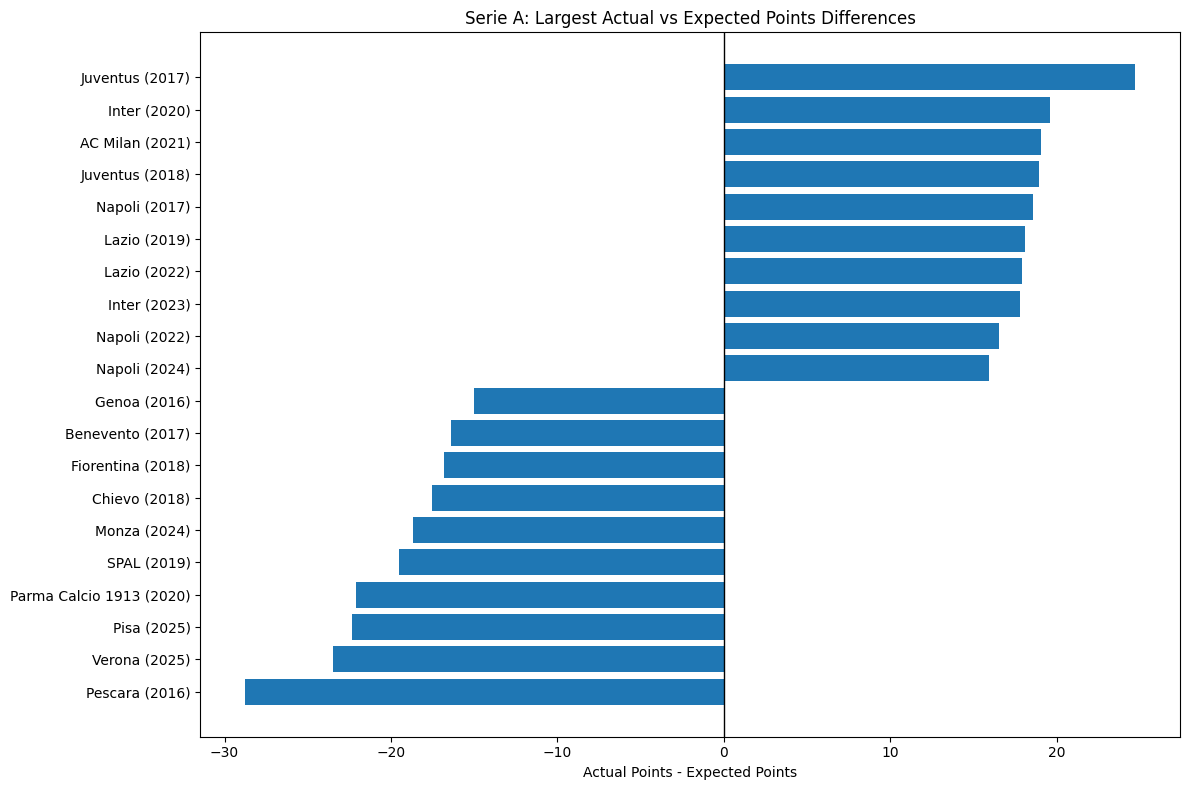

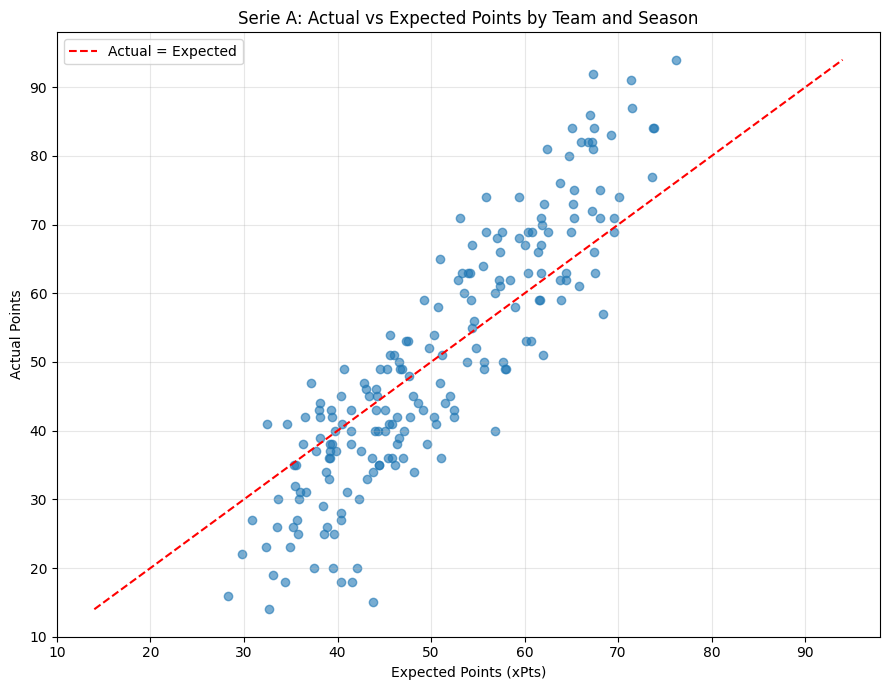

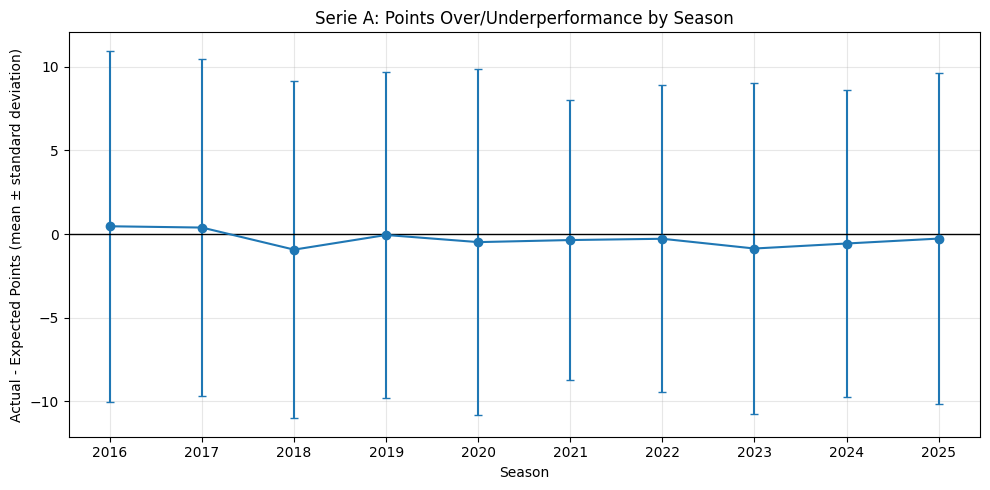

In [51]:


# Question 3 Graphs

# Graph 1: Largest actual vs expected points differences
biggest_over = seasonTable.nlargest(10, "points_diff")
biggest_under = seasonTable.nsmallest(10, "points_diff")
compare = pd.concat([biggest_under, biggest_over]).sort_values("points_diff")

plt.figure(figsize=(12, 8))
plt.barh(compare["team_season"], compare["points_diff"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Serie A: Largest Actual vs Expected Points Differences")
plt.xlabel("Actual Points - Expected Points")
plt.tight_layout()
plt.show()


# Graph 2: Actual vs expected points
plt.figure(figsize=(9, 7))
plt.scatter(
    seasonTable["expected_points"],
    seasonTable["actual_points"],
    alpha=0.6
)

limits = [
    min(seasonTable["expected_points"].min(), seasonTable["actual_points"].min()),
    max(seasonTable["expected_points"].max(), seasonTable["actual_points"].max())
]

plt.plot(limits, limits, "r--", label="Actual = Expected")
plt.title("Serie A: Actual vs Expected Points by Team and Season")
plt.xlabel("Expected Points (xPts)")
plt.ylabel("Actual Points")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Graph 3: Points differences by season
season_diff = seasonTable.groupby("season")["points_diff"].agg(["mean", "std"])

plt.figure(figsize=(10, 5))
plt.errorbar(
    season_diff.index.astype(str),
    season_diff["mean"],
    yerr=season_diff["std"],
    marker="o",
    capsize=3
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Serie A: Points Over/Underperformance by Season")
plt.xlabel("Season")
plt.ylabel("Actual - Expected Points (mean ± standard deviation)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

